## Model 2: Existing Public AI-Text Detection Model

For the second model, we used an existing public AI-text detection model, **Hello-SimpleAI/chatgpt-detector-roberta**, which is a RoBERTa-based transformer model trained for distinguishing **human-written** text from **ChatGPT-generated** text. This model was selected to satisfy the project requirement of using an **existing pre-trained/fine-tuned model** for AI-generated text detection. :contentReference[oaicite:0]{index=0}

Unlike the baseline TF-IDF + Logistic Regression model, this model does not rely on manually designed sparse features. Instead, it uses contextual transformer representations to capture more complex linguistic patterns in text. In this part of the project, the model was used directly for inference on our processed dataset, rather than being trained from scratch.

### Input and Label Setting
Our dataset uses the following label definitions:

- **0 = human-written text**
- **1 = AI-generated text**

The saved train, validation, and test splits produced in the preprocessing stage were loaded, and the model was evaluated on the **test set**.

### Inference Process
The text samples were tokenized using the corresponding Hugging Face tokenizer and then passed to the fine-tuned RoBERTa classifier. Prediction was performed in batches on GPU to improve efficiency. For each input text, the model outputs:

- the predicted label
- the probability score for each class

### Evaluation Metrics
To keep the evaluation consistent with the project requirements, the following quantitative metrics were used:

- **Accuracy**
- **Precision**
- **Recall**
- **F1-score** :contentReference[oaicite:1]{index=1}

### Test Results
The model achieved the following results on the test set:

- **Accuracy:** 0.8241
- **Precision:** 0.8230
- **Recall:** 0.4266
- **F1-score:** 0.5619

These results show that the model performed reasonably well overall, especially in identifying **human-written** texts. However, its recall on the **AI-generated** class was relatively low, which means that many AI-generated samples were still misclassified as human-written text.

### Interpretation
This suggests that the model is relatively **conservative** in predicting the AI-generated class. In other words, when it predicts that a text is AI-generated, it is often correct, but it fails to detect a substantial number of actual AI-generated samples. Therefore, this model serves as a useful comparison point beyond the baseline, while also showing that further improvement is still possible through task-specific fine-tuning or method extension. :contentReference[oaicite:2]{index=2}

In [1]:
import os
import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# =========================
# 1. Check current working directory
# =========================
print("Current working directory:", os.getcwd())

# =========================
# 2. Define paths
# Since this notebook is inside a subfolder,
# use ../ to go back to the project root
# =========================
train_path = "../data/splits/train.parquet"
val_path = "../data/splits/val.parquet"
test_path = "../data/splits/test.parquet"

print("Train exists:", os.path.exists(train_path))
print("Val exists:", os.path.exists(val_path))
print("Test exists:", os.path.exists(test_path))

# =========================
# 3. Load dataset splits
# =========================
train_df = pd.read_parquet(train_path)
val_df = pd.read_parquet(val_path)
test_df = pd.read_parquet(test_path)

print("\nTrain shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTest label distribution:")
print(test_df["label"].value_counts().sort_index())

# =========================
# 4. Device setting
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\nUsing device:", device)

# =========================
# 5. Load an existing public AI-text detection model
# Replace the model name if you choose another one
# =========================
MODEL_NAME = "Hello-SimpleAI/chatgpt-detector-roberta"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print("\nLoaded model:", MODEL_NAME)
print("id2label:", model.config.id2label)
print("label2id:", model.config.label2id)

# =========================
# 6. Prepare test data
# Your label definition:
# human = 0
# ai = 1
# =========================
test_texts = test_df["text"].astype(str).tolist()
y_true = test_df["label"].astype(int).tolist()

# =========================
# 7. Prediction function
# =========================
def predict_in_batches(texts, tokenizer, model, device, batch_size=16, max_length=512):
    all_preds = []
    all_probs = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    return np.array(all_preds), np.array(all_probs)

# =========================
# 8. Run prediction
# =========================
y_pred, y_prob = predict_in_batches(
    test_texts,
    tokenizer,
    model,
    device,
    batch_size=16,
    max_length=512
)

print("\nUnique predicted labels before adjustment:", np.unique(y_pred))

# =========================
# 9. IMPORTANT:
# Check label direction manually
# Your dataset uses:
# 0 = human
# 1 = ai
#
# If the model uses reversed labels,
# uncomment the two lines below
# =========================
# y_pred = 1 - y_pred
# y_prob = y_prob[:, ::-1]

# =========================
# 10. Evaluation
# =========================
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="binary")
recall = recall_score(y_true, y_pred, average="binary")
f1 = f1_score(y_true, y_pred, average="binary")

print("\nExisting Public AI-Text Detection Model Results")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, digits=4))

# =========================
# 11. Save predictions
# Save into the current model folder
# =========================
results_df = test_df.copy()
results_df["pred_existing_model"] = y_pred
results_df["prob_class_0"] = y_prob[:, 0]
results_df["prob_class_1"] = y_prob[:, 1]

output_path = "existing_model_test_predictions.csv"
results_df.to_csv(output_path, index=False)

print("\nSaved predictions to:", output_path)

# =========================
# 12. Quick manual inspection
# =========================
sample_check = pd.DataFrame({
    "text": test_df["text"].head(10),
    "true_label": y_true[:10],
    "pred_label": y_pred[:10]
})

print("\nSample predictions:")
print(sample_check)

d:\python\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Current working directory: d:\COMP6713\group hw\comp6713-ass2\model02_existing_ai_detector
Train exists: True
Val exists: True
Test exists: True

Train shape: (985525, 3)
Validation shape: (211184, 3)
Test shape: (211185, 3)

Test label distribution:
label
0    155352
1     55833
Name: count, dtype: int64

Using device: cuda


d:\python\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\25181\.cache\huggingface\hub\models--Hello-SimpleAI--chatgpt-detector-roberta. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download.


Loaded model: Hello-SimpleAI/chatgpt-detector-roberta
id2label: {0: 'Human', 1: 'ChatGPT'}
label2id: {'ChatGPT': 1, 'Human': 0}


d:\python\Lib\site-packages\torch\nn\modules\module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `RobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)



Unique predicted labels before adjustment: [0 1]

Existing Public AI-Text Detection Model Results
Accuracy : 0.8241
Precision: 0.8230
Recall   : 0.4266
F1-score : 0.5619

Classification Report:
              precision    recall  f1-score   support

           0     0.8243    0.9670    0.8900    155352
           1     0.8230    0.4266    0.5619     55833

    accuracy                         0.8241    211185
   macro avg     0.8236    0.6968    0.7260    211185
weighted avg     0.8240    0.8241    0.8033    211185


Saved predictions to: existing_model_test_predictions.csv

Sample predictions:
                                                text  true_label  pred_label
0  Neither will harm you once they enter your sto...           0           0
1  Gay Marriage as a Civil Rights Issue Essay\n\n...           0           1
2  Economic and Social Problems in the Tampa City...           0           0
3  When the bright light of death began to fade, ...           0           0
4  ``Come her


Confusion Matrix:
[[150228   5124]
 [ 32015  23818]]


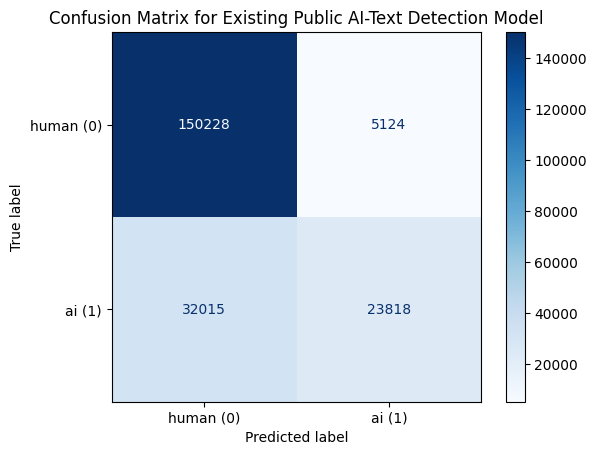

In [2]:
# =========================
# 13. Confusion Matrix
# =========================
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["human (0)", "ai (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix for Existing Public AI-Text Detection Model")
plt.show()